# IT9002 Lab 4.1: Pretrained and Self-Trained Word Embeddings

**Unit 04: Word Embeddings**

**IT9002 Natural Language Processing**

## Objectives

By the end of this lab, you should be able to:

- Explain why one-hot vectors cannot represent similarity between words.
- Use pretrained word embeddings to measure word similarity and identify a word's nearest neighbors.
- Explain how a single training step in skip-gram with negative sampling updates word vectors.
- Interpret word analogy results and identify where they can be unreliable.
- Compare embeddings trained on a small corpus with pretrained embeddings to evaluate their performance.

## Data

- **GloVe 100d** (Pennington, Socher and Manning, 2014), 400,000 word vectors of 100 dimensions trained on Wikipedia 2014 and Gigaword 5, https://nlp.stanford.edu/projects/glove/, Public Domain Dedication and License v1.0.

- **Simple English Wikipedia** (Wikimedia Foundation, dump of 1 November 2023), 50,000 sentences from 1,184 articles, https://huggingface.co/datasets/wikimedia/wikipedia, CC BY-SA 4.0.

- The course file `simple_wikipedia.csv` (on Moodle).

The file `simple_wikipedia.csv` can be downloaded from Moodle. Download it to your computer, then run the cell below. If the file is already available in the runtime, the cell loads it directly; otherwise, it opens a file-upload dialog.

In [1]:
from pathlib import Path
import pandas as pd

DATA = "simple_wikipedia.csv"
path = next((p for p in (Path(DATA), Path("data") / DATA) if p.exists()), None)
if path is None:
    from google.colab import files
    files.upload()
    path = Path(DATA)

wiki = pd.read_csv(path)
print(wiki.shape)
wiki.head()

(50000, 2)


,title,sentence
0,April,It is one of the four months to have 30 days.
1,April,April always begins on the same day of the wee...
2,April,April always ends on the same day of the week ...
3,April,"April comes between March and May, making it t..."
4,April,It also comes first in the year out of the fou...


## Setup

**gensim** is used to load, query, and train word embeddings. The following cell installs gensim and scikit-learn if they are not already installed.

In [2]:
import importlib.util, subprocess, sys

for package, module in (("gensim", "gensim"), ("scikit-learn", "sklearn")):
    if importlib.util.find_spec(module) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)

Imports the libraries and tools required for the lab and displays the installed versions of **pandas**, **NumPy**, and **gensim**.

In [3]:
import collections
import numpy as np
import matplotlib.pyplot as plt
import gensim
import gensim.downloader as api
from gensim.models import Word2Vec
from gensim.test.utils import datapath
from gensim.utils import simple_preprocess
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

print("pandas", pd.__version__, "| NumPy", np.__version__, "| gensim", gensim.__version__)

pandas 3.0.2 | NumPy 2.4.2 | gensim 4.4.0


## 1. One-Hot Vectors

A **one-hot vector** represents a word using one position for each word in the vocabulary. The position corresponding to the word contains the value **1**, while all other positions contain **0**. 

**Bag-of-words** and **TF-IDF** representations follow a similar structure, with one column for each word in the vocabulary.

The following code constructs one-hot vectors for a vocabulary of 5 words and displays a few samples.


In [4]:
vocabulary = ["bridge", "coffee", "cup", "morning", "tea"]
one_hot = {word: np.eye(len(vocabulary))[i] for i, word in enumerate(vocabulary)}
for word in ("coffee", "tea", "bridge"):
    print(f"{word:>6}: {one_hot[word].astype(int)}")

coffee: [0 1 0 0 0]
   tea: [0 0 0 0 1]
bridge: [1 0 0 0 0]


**Cosine similarity** measures how closely two vectors align in direction.

$$\text{cosine}(a, b) = \frac{a \cdot b}{|a| \times |b|}$$

The **dot product** $a \cdot b$ and the **length** $|a|$ of a vector with $n$ positions:

$$a \cdot b = \sum_{i=1}^{n} a_i b_i \qquad\qquad |a| = \sqrt{a \cdot a}$$

`cosine()` calculates the cosine similarity between two vectors and is applied to 2 pairs of one-hot vectors.

In [5]:
def cosine(a, b):
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b)))

print("coffee and tea:", cosine(one_hot["coffee"], one_hot["tea"]))
print("coffee and bridge:", cosine(one_hot["coffee"], one_hot["bridge"]))

coffee and tea: 0.0
coffee and bridge: 0.0


Both values are **0.0**, because two different words never share a position.

A one-hot representation therefore cannot show that `coffee` is closer in meaning to `tea` than to `bridge`.

## 2. Contexts of a Word

The **distributional hypothesis** states that words occurring in similar contexts tend to have similar meanings.

The **context** of a word is the set of words that appear near it in a sentence.

This section counts the context words of `red` and `blue` in the Wikipedia sentences.

`simple_preprocess()` converts each sentence to lowercase and returns its alphabetic tokens of 2-15 characters.

In [6]:
sentences = [simple_preprocess(s) for s in wiki["sentence"]]
print(len(sentences), "sentences |", sum(len(s) for s in sentences), "tokens")
print(sentences[0])

50000 sentences | 724157 tokens
['it', 'is', 'one', 'of', 'the', 'four', 'months', 'to', 'have', 'days']


`contexts()` counts the words that appear within `window` positions (default 2) on each side of a given word, across all sentences. *Stop words are excluded*.

The 8 most frequent context words are displayed for `red` and for `blue`.

In [7]:
def contexts(word, window=2):
    counts = collections.Counter()
    for sentence in sentences:
        for i, token in enumerate(sentence):
            if token == word:
                nearby = sentence[max(0, i - window):i] + sentence[i + 1:i + window + 1]
                counts.update(w for w in nearby if w not in ENGLISH_STOP_WORDS)
    return counts

red, blue = contexts("red"), contexts("blue")
print("red: ", red.most_common(8))
print("blue:", blue.most_common(8))

red:  [('army', 17), ('orange', 11), ('color', 11), ('sea', 11), ('yellow', 10), ('hair', 9), ('green', 8), ('wine', 8)]
blue: [('green', 11), ('color', 10), ('light', 8), ('line', 7), ('yellow', 6), ('red', 6), ('dark', 6), ('mountains', 5)]


The counts of 5 shared context words are placed in one table for both colors.

In [8]:
shared = ["color", "green", "yellow", "white", "light"]
pd.DataFrame({word: [red[word], blue[word]] for word in shared}, index=["red", "blue"])

,color,green,yellow,white,light
red,11,8,10,7,5
blue,10,11,6,5,8


`color` appears **11** times near `red` and **10** times near `blue`, and the other 4 words also appear near both colors.

A model that represents each word by its contexts therefore gives the two colors similar representations.

## 3. Pretrained Word Vectors

A **word embedding** is a dense vector with a small, fixed number of positions, each containing a number.

**Pretrained embeddings** are word vectors that were trained on a large corpus and published for reuse.

This section loads the **GloVe** vectors of 100 dimensions through gensim. The first run downloads **128 MB**.

In [9]:
glove = api.load("glove-wiki-gigaword-100")
print(len(glove.index_to_key), "words |", glove.vector_size, "dimensions")

400000 words | 100 dimensions


The vector of `king` is looked up by its word.

Its shape, the first 6 values, and its position in the vocabulary are displayed.

In [10]:
king = glove["king"]
print(king.shape)
print(king[:6].round(2))
print("position in the vocabulary:", glove.key_to_index["king"])

(100,)
[-0.32 -0.88  0.22  0.25  0.23  0.74]
position in the vocabulary: 691


## 4. Cosine Similarity Between Words

The cosine similarity between two word vectors is **close to 1** when the two words are used in similar contexts and **close to 0** when they are unrelated.

The cosine similarity between `coffee` and `tea` is calculated in three steps: the dot product, the two lengths, and their ratio.

In [11]:
a, b = glove["coffee"], glove["tea"]
dot = float(a @ b)
length_a, length_b = float(np.linalg.norm(a)), float(np.linalg.norm(b))
print("dot product:", round(dot, 3))
print("lengths:", round(length_a, 3), round(length_b, 3))
print("cosine:", round(dot / (length_a * length_b), 3))

dot product: 26.536
lengths: 5.845 5.871
cosine: 0.773


$$\text{cosine}(\text{coffee}, \text{tea}) = \frac{26.536}{5.845 \times 5.871} = 0.773$$

`similarity()` performs the same calculation and is applied to 3 pairs of words.

In [12]:
for first, second in (("coffee", "tea"), ("coffee", "cup"), ("coffee", "bridge")):
    print(f"{first}, {second}: {glove.similarity(first, second):.3f}")

coffee, tea: 0.773
coffee, cup: 0.336
coffee, bridge: 0.087


`coffee` and `tea` have a cosine similarity of **0.773**, while `coffee` and `bridge` have **0.087**.

## 5. Nearest Neighbors

The **nearest neighbors** of a word are the words with the highest cosine similarity to it.

`most_similar()` returns the nearest neighbors of a word, each with its cosine similarity.

The 5 nearest neighbors are displayed for 4 words.

In [13]:
for word in ("hotel", "monday", "france", "hot"):
    neighbors = glove.most_similar(word, topn=5)
    print(f"{word:>6}:", ", ".join(f"{w} {s:.2f}" for w, s in neighbors))

 hotel: hotels 0.79, restaurant 0.78, apartment 0.74, inn 0.73, resort 0.71
monday: tuesday 0.99, thursday 0.99, wednesday 0.99, friday 0.99, saturday 0.92
france: belgium 0.81, french 0.80, britain 0.80, spain 0.76, paris 0.75
   hot: cool 0.77, cold 0.73, warm 0.70, heat 0.68, soft 0.66


The neighbors share a topic or a grammatical role with the word, such as `hotels` and `restaurant` for `hotel`, and the other days of the week for `monday`.

The neighbors of `hot` include `cold`, with a cosine similarity of **0.73**, because opposites appear in the same contexts.

A high cosine similarity therefore indicates that two words are used in similar contexts, even when their meanings differ.

## 6. A Skip-Gram Training Step

**word2vec** learns word embeddings by training a model on a prediction task.

In the **skip-gram** task with **negative sampling**, each training step works on a **center word** and a few pairs of words:

- A **positive pair** combines the center word with a **context word** from its window and has the label 1.

- A **negative sample** is a word drawn at random from the vocabulary. Its pair with the center word has the label 0.

This section carries out a training step with NumPy for the sentence `she drank hot coffee every morning`.

The center word is `coffee`, the context word is `hot`, and the 2 negative samples are `piano` and `tax`.

Every vector has 5 dimensions, so that each number can be checked by hand. The starting vectors are defined first.

In [14]:
coffee = np.array([0.2, -0.4, 0.1, 0.5, -0.3])
context = {"hot": np.array([0.4, -0.1, 0.3, 0.2, 0.1]),
           "piano": np.array([-0.3, 0.2, 0.5, 0.1, 0.4]),
           "tax": np.array([0.5, 0.3, -0.2, 0.4, 0.1])}
label = {"hot": 1, "piano": 0, "tax": 0}

**First:** the **dot product** between the vector of the center word, $c$, and the vector of the other word in the pair, $w$:

$$x = c \cdot w = \sum_{i=1}^{5} c_i w_i$$

The 5 products for `coffee` and `hot` are displayed with their sum, followed by the dot products for the 2 negative samples.

In [15]:
products = coffee * context["hot"]
print("products:", products.round(2))
print("coffee and hot:", round(float(products.sum()), 2))
for word in ("piano", "tax"):
    print(f"coffee and {word}:", round(float(coffee @ context[word]), 2))

products: [ 0.08  0.04  0.03  0.1  -0.03]
coffee and hot: 0.22
coffee and piano: -0.16
coffee and tax: 0.13


The dot product is **0.22** for `hot`, and **−0.16** and **0.13** for the 2 negative samples.

**Second:** the **sigmoid** function converts each dot product into a value between 0 and 1, which is read as the probability that the pair is positive:

$$\sigma(x) = \frac{1}{1 + e^{-x}}$$

**Third:** the **error** of a pair is calculated from its label $y$ and its sigmoid output:

$$\text{error} = y - \sigma(x)$$

`sigmoid()` implements the function.

The output, label, and error are displayed for the pairs.

In [16]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

error = {}
for word, vector in context.items():
    output = sigmoid(coffee @ vector)
    error[word] = label[word] - output
    print(f"{word:>5}: output {output:.3f} | label {label[word]} | error {error[word]:+.3f}")

  hot: output 0.555 | label 1 | error +0.445
piano: output 0.460 | label 0 | error -0.460
  tax: output 0.532 | label 0 | error -0.532


All 3 outputs are close to **0.5**, because the vectors have not been trained yet.

The error is positive for `hot`, where the output should rise toward 1, and negative for `piano` and `tax`, where the outputs should fall toward 0.

**Fourth:** each vector is updated in proportion to the error:

$$w_{\text{new}} = w + \eta \times \text{error} \times c$$

$$c_{\text{new}} = c + \eta \times \sum_{j=1}^{3} \text{error}_j \times w_j$$

$\eta$ is the **learning rate**, which sets the size of each update, and $j$ numbers the 3 pairs.

This example uses a large learning rate of **0.5**, which makes the change visible in three decimals. gensim starts training at 0.025.

The update is applied, and the 4 new vectors are displayed.

In [17]:
learning_rate = 0.5
new_context = {word: vector + learning_rate * error[word] * coffee for word, vector in context.items()}
new_coffee = coffee + learning_rate * sum(error[word] * vector for word, vector in context.items())
for word, vector in new_context.items():
    print(f"{word:>6}: {vector.round(3)}")
print(f"coffee: {new_coffee.round(3)}")

   hot: [ 0.445 -0.189  0.322  0.311  0.033]
 piano: [-0.346  0.292  0.477 -0.015  0.469]
   tax: [ 0.447  0.406 -0.227  0.267  0.18 ]
coffee: [ 0.225 -0.548  0.105  0.415 -0.396]


The fourth position of `hot` changes from 0.2 to:

$$0.2 + 0.5 \times 0.445 \times 0.5 = 0.311$$

The vector of `hot` has moved toward the vector of `coffee`, while the vectors of `piano` and `tax` have moved away from it.

The sigmoid output of each pair is calculated again with the updated vectors.

In [18]:
for word in context:
    before = sigmoid(coffee @ context[word])
    after = sigmoid(new_coffee @ new_context[word])
    print(f"{word:>5}: label {label[word]} | before {before:.3f} | after {after:.3f}")

  hot: label 1 | before 0.555 | after 0.587
piano: label 0 | before 0.460 | after 0.406
  tax: label 0 | before 0.532 | after 0.473


The output for `hot` rises from 0.555 to **0.587**, and the outputs for `piano` and `tax` fall to **0.406** and **0.473**.

One step moves each output closer to its label. Training repeats this step for every pair in every window, so words that appear in similar contexts receive similar updates and similar vectors.

## 7. Word Analogies

A **word analogy** asks for the word that completes a relation, such as the word that relates to `woman` as `king` relates to `man`.

The answer is the word with the vector nearest to:

$$v_{\text{king}} - v_{\text{man}} + v_{\text{woman}}$$

This vector is calculated first from the 3 word vectors, each normalized to a length of 1, and its 3 nearest words are displayed.

`most_similar()` is then applied to the same analogy.

In [19]:
target = glove.get_vector("king", norm=True) - glove.get_vector("man", norm=True) + glove.get_vector("woman", norm=True)
print([(w, round(float(s), 3)) for w, s in glove.similar_by_vector(target, topn=3)])
print([(w, round(float(s), 3)) for w, s in glove.most_similar(positive=["king", "woman"], negative=["man"], topn=3)])

[('king', 0.836), ('queen', 0.77), ('monarch', 0.684)]
[('queen', 0.77), ('monarch', 0.684), ('throne', 0.676)]


The word nearest to the calculated vector is `king` itself, at **0.836**, and `queen` comes second, at **0.770**.

`most_similar()` returns `queen` because it **excludes the 3 words of the question** from the search.

`analogy(a, b, c)` returns the word that relates to `c` as `b` relates to `a`, with its cosine similarity.

In [20]:
def analogy(a, b, c):
    word, score = glove.most_similar(positive=[b, c], negative=[a], topn=1)[0]
    return f"{a} : {b}, {c} : {word} ({score:.3f})"

for a, b, c in (("man", "king", "woman"), ("bahrain", "manama", "qatar"), ("walk", "walking", "swim")):
    print(analogy(a, b, c))

man : king, woman : queen (0.770)
bahrain : manama, qatar : doha (0.679)
walk : walking, swim : swimming (0.801)


The same arithmetic recovers a gender relation (`queen`), a relation between a country and its capital (`doha`), and a grammatical relation (`swimming`).

The expected answers for 3 more analogies are `ottawa`, `canberra`, and `smaller`.

In [21]:
for a, b, c in (("france", "paris", "canada"), ("france", "paris", "australia"), ("big", "bigger", "small")):
    print(analogy(a, b, c))

france : paris, canada : toronto (0.752)
france : paris, australia : sydney (0.832)
big : bigger, small : larger (0.892)


The answers are `toronto`, `sydney`, and `larger`.

The method always returns the nearest word, even when it is not the expected one.

## 8. Visualizing Embeddings in Two Dimensions

**Principal component analysis** (PCA) reduces a set of vectors to a few dimensions that preserve as much of their variation as possible.

This section reduces the vectors of 50 words in 5 groups to two dimensions, so that the words can be plotted. The proportion of the variation preserved is displayed first.

In [22]:
groups = {
    "Drinks and food": ["coffee", "tea", "juice", "milk", "water", "bread", "rice", "cheese", "soup", "sugar"],
    "Animals": ["cat", "dog", "horse", "lion", "rabbit", "tiger", "sheep", "wolf", "bear", "monkey"],
    "Cities": ["paris", "london", "rome", "cairo", "tokyo", "madrid", "berlin", "moscow", "dubai", "manama"],
    "Occupations": ["doctor", "nurse", "teacher", "engineer", "lawyer", "pilot", "chef", "farmer", "banker", "judge"],
    "Days and months": ["monday", "tuesday", "friday", "sunday", "january", "march", "june", "july", "october", "december"],
}
words = [word for group in groups.values() for word in group]
pca = PCA(n_components=2, random_state=0)
points = pca.fit_transform(np.array([glove[word] for word in words]))
print("variation kept by two dimensions:", round(float(pca.explained_variance_ratio_.sum()), 3))

variation kept by two dimensions: 0.327


The two dimensions keep **0.327** of the variation, so the plot is an approximation of the positions in 100 dimensions.

The 50 words are plotted with one color for each group.

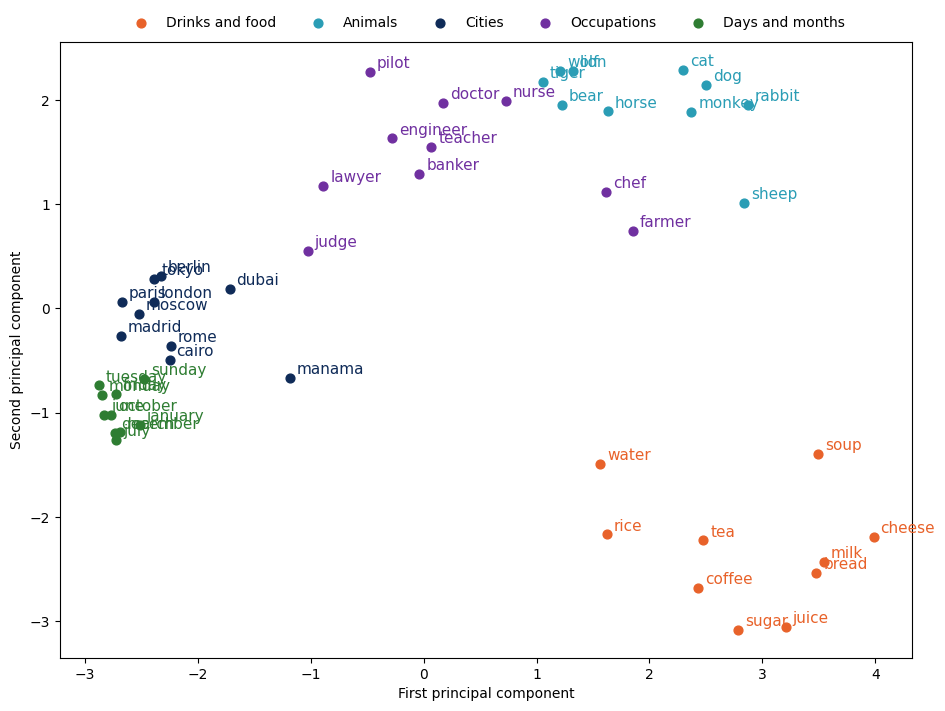

In [23]:
colors = ["#E8622A", "#2A9DB5", "#0F2B58", "#7030A0", "#2E7D32"]
fig, ax = plt.subplots(figsize=(11, 8))
for k, (name, group) in enumerate(groups.items()):
    xy = points[k * 10:(k + 1) * 10]
    ax.scatter(xy[:, 0], xy[:, 1], color=colors[k], s=40, label=name)
    for (x, y), word in zip(xy, group):
        ax.annotate(word, (x, y), xytext=(5, 3), textcoords="offset points", color=colors[k], fontsize=11)
ax.set_xlabel("First principal component")
ax.set_ylabel("Second principal component")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=5, frameon=False)
plt.show()

The words in each group lie close together, although the groups were used only for the colors and played no part in terms of positioning.

The days and months form the tightest group, which matches the cosine similarity of 0.99 between `monday` and its nearest neighbors.

## 9. Training word2vec on Wikipedia Sentences

This section trains word2vec on the 50,000 Wikipedia sentences with gensim's `Word2Vec`, which receives the sentences as lists of tokens.

The settings are:

- `vector_size=100`: the number of dimensions in each vector.

- `window=5`: the number of words taken on each side of the center word.

- `min_count=5`: words that occur fewer than 5 times receive no vector.

- `sg=1`: the skip-gram task. The default, `sg=0`, is the continuous bag of words (CBOW) task.

- `negative=5`: the number of negative samples for each positive pair.

- `epochs=5`: the number of passes through the corpus.

- `seed=42` and `workers=1`: a fixed starting point and a single process, so that the same run gives the same vectors.

The size of the vocabulary and the shape of the embedding matrix are displayed after training.

In [24]:
model = Word2Vec(sentences, vector_size=100, window=5, min_count=5, sg=1, negative=5, epochs=5, seed=42, workers=1)
print("vocabulary:", len(model.wv), "| embedding matrix:", model.wv.vectors.shape)

vocabulary: 9634 | embedding matrix: (9634, 100)


The model keeps **9,634 words**, each of which occurs at least 5 times in the corpus.

Its **embedding matrix** has one row for each word and one column for each dimension, and the embedding of a word is its row.

## 10. Comparing Self-Trained and Pretrained Embeddings

The self-trained model was trained on **724,157 tokens**, while the pretrained vectors were trained on **6 billion**.

For 3 words, the number of occurrences in the corpus and the 5 nearest neighbors in both models are displayed.

In [25]:
counts = collections.Counter(token for sentence in sentences for token in sentence)
for word in ("music", "planet", "horse"):
    print(f"{word} (occurs {counts[word]} times)")
    print("   self-trained:", [w for w, _ in model.wv.most_similar(word, topn=5)])
    print("   pretrained:  ", [w for w, _ in glove.most_similar(word, topn=5)])

music (occurs 459 times)
   self-trained: ['pop', 'jazz', 'dance', 'classical', 'art']
   pretrained:   ['musical', 'songs', 'dance', 'pop', 'recording']
planet (occurs 253 times)
   self-trained: ['uranus', 'saturn', 'moon', 'neptune', 'jupiter']
   pretrained:   ['earth', 'mars', 'planets', 'universe', 'pluto']
horse (occurs 26 times)
   self-trained: ['handheld', 'aerial', 'plum', 'grid', 'intel']
   pretrained:   ['horses', 'riding', 'dog', 'racing', 'bike']


`music` occurs **459** times, and its self-trained neighbors should include `pop`, `jazz`, and `dance`.

`planet` occurs **253** times, and its self-trained neighbors should include `saturn`, `neptune`, and `jupiter`.

`horse` occurs only **26** times, and its self-trained neighbors are unrelated words, while its pretrained neighbors include `horses` and `riding`.

The quality of a word's vector depends on how often the word was seen in training, so a small corpus is unreliable for rare words.

## 11. Evaluating Embeddings with Similarity and Analogy Tests

**Intrinsic evaluation** tests embeddings directly on word-level questions with known answers.

Two published tests are installed with gensim:

- **WordSim-353** (Finkelstein et al., 2001) contains 353 word pairs scored by people. The cosine similarities of a model are compared with the human scores by a **rank correlation**, where 1 means the same ranking.

- The **Google analogy set** (Mikolov et al., 2013) contains 19,544 analogy questions in 14 categories. A question is answered correctly when the nearest word is the expected answer.

$$\text{analogy accuracy} = \frac{\text{questions answered correctly}}{\text{questions attempted}}$$

Both models are evaluated on WordSim-353 first.

In [26]:
for name, vectors in (("pretrained", glove), ("self-trained", model.wv)):
    pearson, spearman, missing = vectors.evaluate_word_pairs(datapath("wordsim353.tsv"))
    print(f"{name:>12}: rank correlation {spearman.statistic:.3f} | pairs with a missing word {missing:.1f}%")

  pretrained: rank correlation 0.533 | pairs with a missing word 0.0%
self-trained: rank correlation 0.383 | pairs with a missing word 32.6%


The pretrained vectors reach a rank correlation of **0.533**.

The self-trained model should reach about **0.38**, and it lacks a word in about 33% of the pairs.

Both models are then evaluated on the analogy set.

`restrict_vocab=100000` limits the search to the 100,000 most frequent words, and a question is skipped when one of its words is missing.

In [27]:
accuracy, sections = glove.evaluate_word_analogies(datapath("questions-words.txt"), restrict_vocab=100000)
answered = len(sections[-1]["correct"]) + len(sections[-1]["incorrect"])
print(f"  pretrained: accuracy {accuracy:.3f} on {answered} questions")
accuracy_self, sections_self = model.wv.evaluate_word_analogies(datapath("questions-words.txt"), restrict_vocab=100000)
answered_self = len(sections_self[-1]["correct"]) + len(sections_self[-1]["incorrect"])
print(f"self-trained: accuracy {accuracy_self:.3f} on {answered_self} questions")

  pretrained: accuracy 0.639 on 19230 questions
self-trained: accuracy 0.067 on 5952 questions


The pretrained vectors reach an analogy accuracy of **0.639** on 19,230 questions.

The self-trained model can attempt only about 6,000 questions and should reach about **0.07**.

The analogy accuracy of the pretrained vectors is plotted for each of the 14 categories.

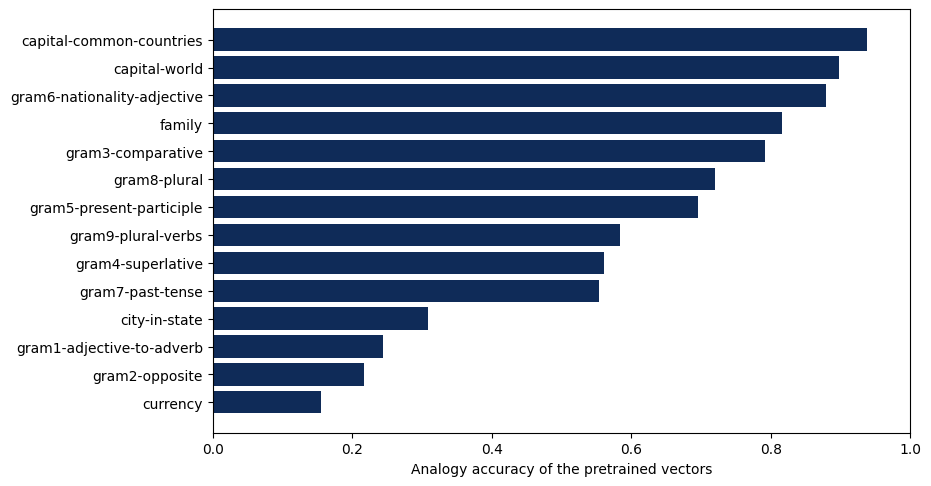

In [28]:
names = [s["section"] for s in sections[:-1]]
scores = [len(s["correct"]) / (len(s["correct"]) + len(s["incorrect"])) for s in sections[:-1]]
order = np.argsort(scores)
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh([names[i] for i in order], [scores[i] for i in order], color="#0F2B58")
ax.set_xlabel("Analogy accuracy of the pretrained vectors")
ax.set_xlim(0, 1)
plt.show()

The accuracy differs widely between categories, from about **0.94** for the capitals of common countries to about **0.16** for currencies.

A single accuracy for the whole set hides this difference, so the result of an analogy test should be read by category.

## Exercises

### Exercise 1: Similarity of Opposites

Display the **cosine similarity** between the pretrained vectors of 3 pairs: `rose` and `fell`, `increase` and `decrease`, and `buy` and `sell`.

In a Markdown cell, explain why the values are high although the words in each pair have opposite meanings.

In [ ]:
# TODO: Print the cosine similarity of the 3 pairs of opposites.


**Expected result:** The 3 values are **0.883**, **0.881**, and **0.938**.

The words in each pair appear in the same contexts, such as `sales rose 5%` and `sales fell 5%`, so their vectors are close together.

### Exercise 2: Capital Analogies

Use `analogy()` to answer the analogy `france : paris` for **6 countries**: `italy`, `japan`, `egypt`, `canada`, `australia`, and `brazil`.

In a Markdown cell, state which answers are the capital of the country and what the wrong answers have in common.

In [30]:
# TODO: Print the answer of the analogy france : paris for the 6 countries.


**Expected result:** The answers `rome`, `tokyo`, and `cairo` are capitals, while `toronto`, `sydney`, and `janeiro` are not.

In the 3 wrong answers, the best-known city in the country is mentioned more often than its capital.

### Exercise 3: Training on a Smaller Corpus

Train `Word2Vec` with the settings of section 9 on a random sample of **10,000 sentences**, drawn with `np.random.RandomState(42).choice(len(sentences), 10000, replace=False)`.

Report:

- The size of the vocabulary.

- The 5 nearest neighbors of `music` and of `planet`.

- Whether `horse` is in the vocabulary.

In [31]:
# TODO: Train Word2Vec on 10,000 sentences and print the vocabulary size, the neighbors of music and planet, and whether horse has a vector.


**Expected results:**

- The vocabulary falls to about **3,500 words**.

- The neighbors of `music` and of `planet` are mostly unrelated words, although `music` still occurs 94 times in the sample.

- `horse` occurs fewer than 5 times in the sample, so it has no vector.

### Exercise 4 (Extension): Effect of the Window Size

Train `Word2Vec` twice on all sentences with the settings of section 9, once with `window=2` and once with `window=10`.

Display the 6 nearest neighbors of `play` and of `eat` in both models.

In a Markdown cell, state which type of word forms most of the neighbors for each window size.

The two types are words with the same grammatical role and words on the same topic.

In [32]:
# TODO: Train Word2Vec with window=2 and window=10 and print the 6 nearest neighbors of play and eat in both models.


**Expected result:** With a window of 2, the neighbors should be mostly other verbs, such as `compete` and `serve` for `play`, and `wear` and `collect` for `eat`.

With a window of 10, the neighbors should be mostly words on the same topic, such as `games` and `players` for `play`, and `insects` and `grass` for `eat`.

A small window groups words with the same grammatical role, while a large window groups words on the same topic.